# Electricity demand in France: temperature, sobriety and forecasting

**Objective:** explain and forecast the daily electricity consumption of France with the temperature and the calendar, and measure how much demand fell during the energy crisis of 2022-2023 once we remove the effect of the weather.

**Data (Open Data Réseaux Énergies, RTE):**
- eco2mix national consolidated data, consumption every 30 minutes since 2012 (`eco2mix-national-cons-def`)
- Daily regional temperatures since 2016 (`temperature-quotidienne-regionale`)

Libraries of the project: `pandas`, `numpy`, `matplotlib`, `seaborn`, `requests`, `dateutil` and `scikit-learn`.

## Part 1. Libraries

In [1]:
import io
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from dateutil.easter import easter

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_percentage_error

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

## Part 2. Download daily data

The API of ODRE can aggregate the data before sending it: we ask for the average power of each day (MW) and the average temperature of the French regions of each day.

In [2]:
def odre(dataset, select, nombre):
    ruta = f"data/{nombre}.csv"
    if not os.path.exists(ruta):
        url = f"https://odre.opendatasoft.com/api/explore/v2.1/catalog/datasets/{dataset}/exports/csv"
        r = requests.get(url, params={"select": select, "group_by": "date", "order_by": "date", "delimiter": ","}, timeout=600)
        with open(ruta, "w", encoding="utf-8") as f:
            f.write(r.text)
    return pd.read_csv(ruta, parse_dates=["date"])

conso = odre("eco2mix-national-cons-def", "date, avg(consommation) as mw", "consumption_daily")
temp = odre("temperature-quotidienne-regionale", "date, avg(tmoy) as temp", "temperature_daily")
temp["date"] = pd.to_datetime(temp["date"]).dt.tz_localize(None)

df = conso.merge(temp, on="date", how="left")
df["gwh"] = df["mw"] * 24 / 1000            # energy of the day
df = df.dropna(subset=["gwh"]).set_index("date").sort_index()
print("Consumption from", df.index.min().date(), "to", df.index.max().date())
print("Temperature from", temp["date"].min().date())
df.tail()

Consumption from 2012-01-01 to 2026-08-31
Temperature from 2016-01-01


,mw,temp,gwh
date,,,
2026-08-27,45794.666667,23.822308,1099.0720
2026-08-28,44988.979167,21.503846,1079.7355
2026-08-29,40539.666667,20.693077,972.9520
2026-08-30,38906.625000,21.812308,933.7590
2026-08-31,44279.958333,NaN,1062.7190


## Part 3. A first look

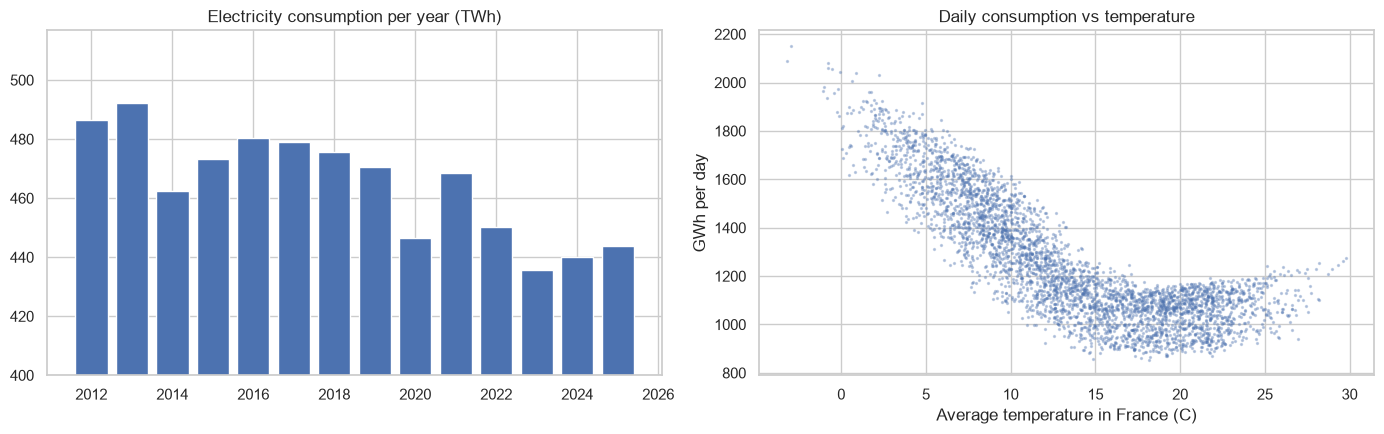

date
2012    486.6
2013    492.2
2014    462.3
2015    473.2
2016    480.3
2017    479.0
2018    475.5
2019    470.5
2020    446.6
2021    468.6
2022    450.2
2023    435.6
2024    440.1
2025    443.9
Name: gwh, dtype: float64

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
anual = df["gwh"].groupby(df.index.year).sum() / 1000
anual = anual[df.groupby(df.index.year).size() >= 360]       # only complete years
axes[0].bar(anual.index, anual.values)
axes[0].set_ylim(400, anual.max() * 1.05)
axes[0].set_title("Electricity consumption per year (TWh)")
d = df.dropna(subset=["temp"])
axes[1].scatter(d["temp"], d["gwh"], s=2, alpha=0.3)
axes[1].set_title("Daily consumption vs temperature")
axes[1].set_xlabel("Average temperature in France (C)")
axes[1].set_ylabel("GWh per day")
plt.tight_layout()
plt.savefig("figures/consumption_overview.png", bbox_inches="tight")
plt.show()
anual.round(1)

France uses electric heating a lot, so the consumption grows fast when the temperature goes down. In summer there is only a small increase with the heat (air conditioning). We can also see the fall of 2020 (lockdowns) and of 2022-2023 (energy crisis).

## Part 4. Variables for the model

- HDD (heating degree days) = max(15 - T, 0) and CDD (cooling degree days) = max(T - 22, 0)
- Day of the week, month and public holidays (fixed dates and the ones that depend on Easter)
- The temperature of the day before (buildings take time to get cold)

In [4]:
def festivos(anio):
    fijos = [(1, 1), (5, 1), (5, 8), (7, 14), (8, 15), (11, 1), (11, 11), (12, 25)]
    dias = [pd.Timestamp(anio, m, d) for m, d in fijos]
    p = pd.Timestamp(easter(anio))
    dias += [p + pd.Timedelta(days=1), p + pd.Timedelta(days=39), p + pd.Timedelta(days=50)]   # Easter Monday, Ascension, Whit Monday
    return dias

lista = [f for a in range(2012, 2027) for f in festivos(a)]
df["holiday"] = df.index.isin(lista).astype(int)
df["hdd"] = (15 - df["temp"]).clip(lower=0)
df["cdd"] = (df["temp"] - 22).clip(lower=0)
df["hdd_lag"] = df["hdd"].shift(1)
df["dow"] = df.index.dayofweek
df["month"] = df.index.month
df["year"] = df.index.year
df["christmas"] = ((df.index.month == 12) & (df.index.day >= 24) | (df.index.month == 1) & (df.index.day <= 2)).astype(int)
datos = df.dropna(subset=["temp", "hdd_lag"])

## Part 5. Thermosensitivity with a linear regression

We fit the model with the years before the crisis (2016-2021), so we can use it later to see what "normal" consumption would have been.

In [5]:
x_cols = ["hdd", "hdd_lag", "cdd", "holiday", "christmas"]
x = pd.get_dummies(datos[x_cols + ["dow", "month"]], columns=["dow", "month"], drop_first=True).astype(float)
y = datos["gwh"]
antes = (datos.index >= "2016-01-01") & (datos.index < "2022-01-01") & ~((datos.index >= "2020-03-15") & (datos.index < "2020-07-01"))
lr = LinearRegression().fit(x[antes], y[antes])
print("R2 (2016-2021, without the first lockdown):", round(lr.score(x[antes], y[antes]), 3))
print("Each degree below 15 C adds:", round((lr.coef_[0] + lr.coef_[1]) / 24 * 1000), "MW")
print("Each degree above 22 C adds:", round(lr.coef_[2] / 24 * 1000), "MW")

R2 (2016-2021, without the first lockdown): 0.974
Each degree below 15 C adds: 1826 MW
Each degree above 22 C adds: 763 MW


The famous rule of RTE is that every degree less in winter adds around 2.400 MW of consumption in France. Our simple model gives a number of the same order.

## Part 6. How much did France save in the energy crisis?

We use the model trained before 2022 to predict the consumption with the real temperatures of each day, and we compare it with the real consumption. The difference is the reduction that the weather does not explain (prices, sobriety plan, industry producing less).

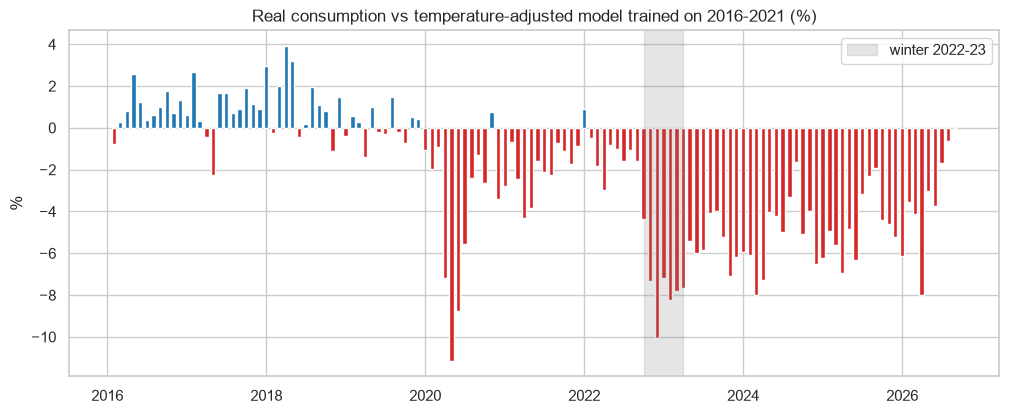

Winter 2022-23 | real vs expected: -8.0 %
Winter 2023-24 | real vs expected: -6.7 %
Winter 2024-25 | real vs expected: -5.7 %
Winter 2025-26 | real vs expected: -5.3 %


In [6]:
datos = datos.assign(pred_lr=lr.predict(x))
datos["gap_%"] = (datos["gwh"] / datos["pred_lr"] - 1) * 100
gap_mes = datos["gap_%"].resample("ME").mean()
plt.figure(figsize=(12, 4.5))
plt.bar(gap_mes.index, gap_mes.values, width=20, color=np.where(gap_mes.values < 0, "tab:red", "tab:blue"))
plt.axvspan(pd.Timestamp("2022-10-01"), pd.Timestamp("2023-03-31"), color="grey", alpha=0.2, label="winter 2022-23")
plt.title("Real consumption vs temperature-adjusted model trained on 2016-2021 (%)")
plt.ylabel("%")
plt.legend()
plt.savefig("figures/crisis_gap.png", bbox_inches="tight")
plt.show()
for a, b in [("2022-10-01", "2023-03-31"), ("2023-10-01", "2024-03-31"), ("2024-10-01", "2025-03-31"), ("2025-10-01", "2026-03-31")]:
    print("Winter", a[:4] + "-" + b[2:4], "| real vs expected:", round(datos.loc[a:b, "gap_%"].mean(), 1), "%")

## Part 7. Forecasting model

Now the objective is to forecast well, so we use all the history and a gradient boosting with a time trend. We train until the end of 2024 and test on 2025-2026, against two simple benchmarks: the same day of the last week and the linear regression.

In [7]:
x2 = x.copy()
x2["temp"] = datos["temp"]
x2["t"] = (datos.index - datos.index[0]).days
train = datos.index < "2025-01-01"
test = ~train

gb = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, random_state=42).fit(x2[train], y[train])
lr2 = LinearRegression().fit(x2[train], y[train])
pred_gb = gb.predict(x2[test])
pred_lr2 = lr2.predict(x2[test])
naive = datos["gwh"].shift(7)[test]

print("Test from", datos.index[test].min().date(), "to", datos.index[test].max().date())
print("MAPE same day last week:", round(mean_absolute_percentage_error(y[test], naive) * 100, 2), "%")
print("MAPE linear regression:", round(mean_absolute_percentage_error(y[test], pred_lr2) * 100, 2), "%")
print("MAPE gradient boosting:", round(mean_absolute_percentage_error(y[test], pred_gb) * 100, 2), "%")

Test from 2025-01-02 to 2026-08-30
MAPE same day last week: 7.01 %
MAPE linear regression: 3.98 %
MAPE gradient boosting: 3.91 %


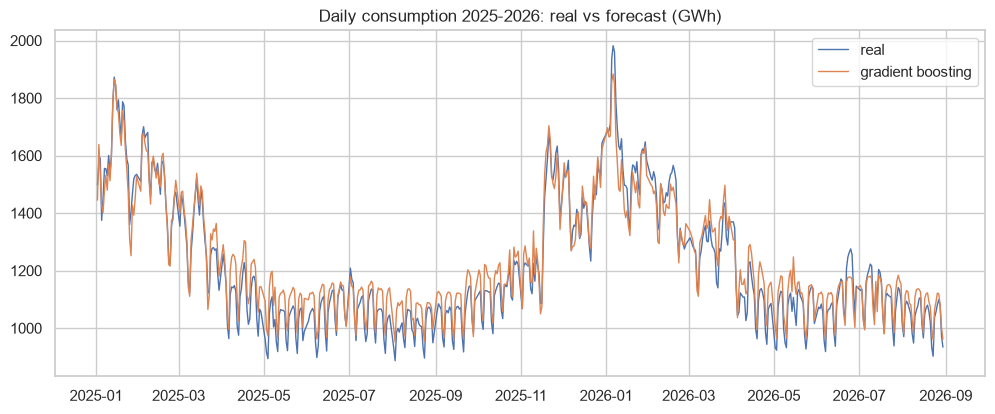

In [8]:
plt.figure(figsize=(12, 4.5))
plt.plot(datos.index[test], y[test], label="real", lw=1)
plt.plot(datos.index[test], pred_gb, label="gradient boosting", lw=1)
plt.title("Daily consumption 2025-2026: real vs forecast (GWh)")
plt.legend()
plt.savefig("figures/forecast_test.png", bbox_inches="tight")
plt.show()

## Conclusions

- Temperature is the main driver of the electricity demand in France: with temperature and calendar the linear model explains 97% of the daily variation, and every degree below 15 C adds around 1.800 MW.
- After removing the effect of temperature, consumption in the winter of 2022-2023 was 8% below what the model expected. The gap is getting smaller (-5% in the winter 2025-26) but demand has not come back to the levels before the crisis: part of the savings stayed (more efficient habits, less industrial demand).
- With only temperature and calendar variables, both the linear regression and the gradient boosting forecast the daily consumption of 2025-2026 with a MAPE close to 4%, almost half of the naive forecast (7%). Here the boosting adds very little over a good linear model, so the simple model is enough.